In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_orders = pd.read_csv("dataset/olist_orders_dataset.csv")
df_orders.head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [2]:
status = df_orders [(df_orders["order_status"] == "canceled") | (df_orders["order_status"] == "unavailable")]
order = len(status)
print("jumlah order yang dibatalkan atau tidak tersedia: ",order)
status.head(5)

jumlah order yang dibatalkan atau tidak tersedia:  1234


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
266,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaN,NaN,2017-12-05 00:00:00
397,1b9ecfe83cdc259250e1a8aca174f0ad,6d6b50b66d79f80827b6d96751528d30,canceled,2018-08-04 14:29:27,2018-08-07 04:10:26,NaN,NaN,2018-08-14 00:00:00
586,c272bcd21c287498b4883c7512019702,9582c5bbecc65eb568e2c1d839b5cba1,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50,NaN,NaN,2018-02-16 00:00:00
613,714fb133a6730ab81fa1d3c1b2007291,e3fe72696c4713d64d3c10afe71e75ed,canceled,2018-01-26 21:34:08,2018-01-26 21:58:39,2018-01-29 22:33:25,NaN,2018-02-22 00:00:00
687,37553832a3a89c9b2db59701c357ca67,7607cd563696c27ede287e515812d528,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18,NaN,NaN,2017-09-05 00:00:00


In [3]:
df_items= pd.read_csv("dataset/olist_order_items_dataset.csv")
df_sellers = pd.read_csv("dataset/olist_sellers_dataset.csv")

df_oi = pd.merge(df_sellers,df_items, on = "seller_id", how = "inner")

seller_tertinggi = df_oi.groupby("seller_state")["price"].sum().reset_index().sort_values("price", ascending = False)

display(seller_tertinggi)

,seller_state,price
22,SP,8753396.21
15,PR,1261887.21
8,MG,1011564.74
16,RJ,843984.22
20,SC,632426.07
19,RS,378559.54
2,BA,285561.56
4,DF,97749.48
13,PE,91493.85
6,GO,66399.21


In [4]:
df_orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [5]:
df_orders_clean = df_orders.dropna(subset=["order_approved_at"])
df_orders_clean.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1637
order_delivered_customer_date    2819
order_estimated_delivery_date       0
dtype: int64

In [6]:
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
df_orders["order_purchase_timestamp"] = pd.to_datetime(df_orders["order_purchase_timestamp"])
df_orders["order_year"] = df_orders["order_purchase_timestamp"].dt.year
tren_tahun = df_orders["order_year"].value_counts().sort_index().reset_index()
display(tren_tahun)

,order_year,count
0,2016,329
1,2017,45101
2,2018,54011


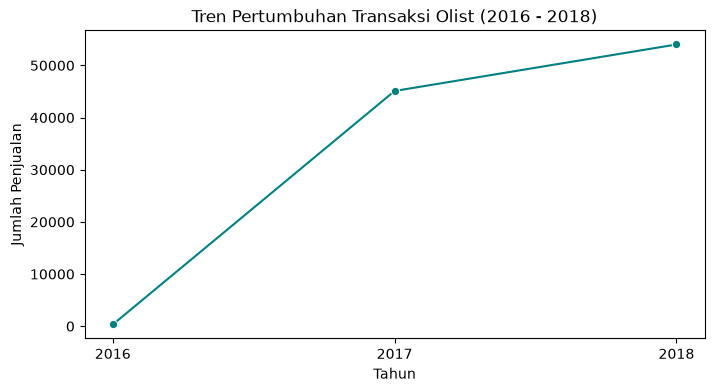

In [ ]:
plt.figure(figsize=(8,4))
sns.lineplot(data = tren_tahun, x = "order_year", y = "count", marker = "o", color = "teal")

plt.xticks(tren_tahun["order_year"])

plt.title("Tren Pertumbuhan Transaksi Olist (2016 - 2018)")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Penjualan")
plt.show()

In [9]:
df_order_composite = pd.merge(df_orders, df_items, on = "order_id", how = "inner")
customer_rfm_based = df_order_composite.groupby("customer_id").agg(
    frequency = ("order_id", "count"),
    monetary = ("price", "sum")
).reset_index()

customer_rfm_based.head(5)

,customer_id,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,1,89.80
1,000161a058600d5901f007fab4c27140,1,54.90
2,0001fd6190edaaf884bcaf3d49edf079,1,179.99
3,0002414f95344307404f0ace7a26f1d5,1,149.90
4,000379cdec625522490c315e70c7a9fb,1,93.00


In [10]:
df_order_composite.info()
max_date = df_order_composite["order_purchase_timestamp"].max()
customer_recency = df_order_composite.groupby("customer_id")["order_purchase_timestamp"].max().reset_index()
customer_recency["recency"] = (max_date - customer_recency["order_purchase_timestamp"]).dt.days

customer_recency.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 15 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  str           
 1   customer_id                    112650 non-null  str           
 2   order_status                   112650 non-null  str           
 3   order_purchase_timestamp       112650 non-null  datetime64[us]
 4   order_approved_at              112635 non-null  str           
 5   order_delivered_carrier_date   111456 non-null  str           
 6   order_delivered_customer_date  110196 non-null  str           
 7   order_estimated_delivery_date  112650 non-null  str           
 8   order_year                     112650 non-null  int32         
 9   order_item_id                  112650 non-null  int64         
 10  product_id                     112650 non-null  str           
 11  seller_id  

,customer_id,order_purchase_timestamp,recency
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,292
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,413
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,551
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,382
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,153


In [11]:
rfm_merge = pd.merge(customer_rfm_based, customer_recency, on = "customer_id", how = "inner")
rfm_final = rfm_merge[["customer_id", "recency", "frequency", "monetary"]]
rfm_final.head(5)

,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,292,1,89.80
1,000161a058600d5901f007fab4c27140,413,1,54.90
2,0001fd6190edaaf884bcaf3d49edf079,551,1,179.99
3,0002414f95344307404f0ace7a26f1d5,382,1,149.90
4,000379cdec625522490c315e70c7a9fb,153,1,93.00


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X_rfm = rfm_final[["recency", "frequency", "monetary"]]

scaler = StandardScaler()
X_rfm_Scaled = scaler.fit_transform(X_rfm)

kmeans = KMeans(n_clusters=3, random_state=42)
rfm_final["cluster"] = kmeans.fit_predict(X_rfm_Scaled)
rfm_final.head(5)

,customer_id,recency,frequency,monetary,cluster
0,00012a2ce6f8dcda20d059ce98491703,292,1,89.80,0
1,000161a058600d5901f007fab4c27140,413,1,54.90,0
2,0001fd6190edaaf884bcaf3d49edf079,551,1,179.99,0
3,0002414f95344307404f0ace7a26f1d5,382,1,149.90,0
4,000379cdec625522490c315e70c7a9fb,153,1,93.00,1


In [25]:
rfm_profile = rfm_final.groupby("cluster")[["recency", "frequency", "monetary"]].mean().round(2).reset_index()
display(rfm_profile)

,cluster,recency,frequency,monetary
0,0,399.37,1.03,113.97
1,1,134.94,1.00,111.33
2,2,218.93,2.30,371.72


In [26]:
segmen_dict = {
    0 : "At Risk / Hibernating",
    1 : "Active New Buyers",
    2 : "Champions / VIP"
}

rfm_final["customer_segment"] = rfm_final["cluster"].map(segmen_dict)

rfm_final.head(5)

,customer_id,recency,frequency,monetary,cluster,customer_segment
0,00012a2ce6f8dcda20d059ce98491703,292,1,89.80,0,At Risk / Hibernating
1,000161a058600d5901f007fab4c27140,413,1,54.90,0,At Risk / Hibernating
2,0001fd6190edaaf884bcaf3d49edf079,551,1,179.99,0,At Risk / Hibernating
3,0002414f95344307404f0ace7a26f1d5,382,1,149.90,0,At Risk / Hibernating
4,000379cdec625522490c315e70c7a9fb,153,1,93.00,1,Active New Buyers


In [27]:
rfm_final.to_csv("dataset/olist_rfm_segmented.csv", index = False)